# 1. Identificación de la Problemática:
Análisis de la aplicación de nuevas tecnologías como fuentes alternativas de energía en Colombia

In [87]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

# 2. Recolección de Datos:


In [88]:
df_B = pd.read_csv(
    "/content/datosplanb.csv",
    sep=",",
    encoding="utf-8-sig"
)

df_B.head()

,Proyecto,Tipo,Capacidad,Departamento,Municipio,Código Departamento,Código Municipio,Fecha estimada FPO,Energía [kWh/día],Usuarios,Inversión estimada [COP],Empleos estimados,Emisiones CO2 [Ton/año]
0,JEPIRACHI,Eólico,18.42,LA GUAJIRA,URIBIA,44,44847,2004-04-27T00:00:00.000,176832,30665,79206000000,51,51635
1,AUTOG CELSIA SOLAR YUMBO,Solar,9.80,VALLE DEL CAUCA,YUMBO,76,76892,2017-03-09T00:00:00.000,47040,8157,42140000000,68,13736
2,CELSIA SOLAR BOLIVAR,Solar,8.06,BOLÍVAR,SANTA ROSA,13,13683,2019-02-01T00:00:00.000,38688,6709,34658000000,56,11297
3,EL PASO SOLAR (ENEL GREEN POWER),Solar,67.00,CESAR,EL PASO,20,20250,2019-04-05T00:00:00.000,321600,55769,288100000000,466,93907
4,SOLAR CASTILLA ECP,Solar,20.00,META,CASTILLA LA NUEVA,50,50150,2019-10-10T00:00:00.000,96000,16647,86000000000,139,28032


In [89]:
df_B.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 158 entries, 0 to 157
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Proyecto                  158 non-null    object 
 1   Tipo                      158 non-null    object 
 2   Capacidad                 158 non-null    float64
 3   Departamento              158 non-null    object 
 4   Municipio                 158 non-null    object 
 5   Código Departamento       158 non-null    int64  
 6   Código Municipio          158 non-null    int64  
 7   Fecha estimada FPO        158 non-null    object 
 8   Energía [kWh/día]         158 non-null    int64  
 9   Usuarios                  158 non-null    int64  
 10  Inversión estimada [COP]  158 non-null    int64  
 11  Empleos estimados         158 non-null    int64  
 12  Emisiones CO2 [Ton/año]   158 non-null    int64  
dtypes: float64(1), int64(7), object(5)
memory usage: 16.2+ KB


In [90]:
df_B.describe()

,Capacidad,Código Departamento,Código Municipio,Energía [kWh/día],Usuarios,Inversión estimada [COP],Empleos estimados,Emisiones CO2 [Ton/año]
count,158.000000,158.000000,158.000000,1.580000e+02,158.000000,1.580000e+02,158.000000,158.000000
mean,37.971646,42.829114,41551.797468,2.312960e+05,40109.063291,1.450582e+11,221.607595,67538.462025
std,78.068671,26.605922,27283.549553,5.070385e+05,87925.819429,2.938303e+11,485.174312,148055.230112
min,0.010000,5.000000,23.000000,2.100000e+01,4.000000,9.800000e+06,0.000000,6.000000
25%,2.275000,17.500000,13675.500000,1.092000e+04,1893.750000,9.513750e+09,16.000000,3189.000000
50%,9.900000,44.000000,44847.000000,4.752000e+04,8240.000000,3.963250e+10,69.000000,13876.000000
75%,20.750000,70.000000,68514.750000,1.123800e+05,19487.750000,8.557000e+10,144.250000,32814.750000
max,700.000000,94.000000,94001.000000,3.360000e+06,582659.000000,2.625000e+12,4872.000000,981120.000000


In [91]:
df_B.isnull().values.any()

np.False_

#**LIMPIEZA DE LOS DATOS**

# 3. Exploración y Limpieza de Datos:

In [92]:
df_B.columns = df_B.columns.str.strip()
for col in df_B.select_dtypes(include=['object']).columns:
    df_B[col] = df_B[col].str.strip()

In [93]:
cols_texto = ['Proyecto', 'Tipo', 'Departamento', 'Municipio']
for col in cols_texto:
    df_B[col] = df_B[col].str.upper()

In [94]:
df_B['Fecha estimada FPO'] = pd.to_datetime(df_B['Fecha estimada FPO'], errors='coerce')

In [95]:
df_B.replace("", pd.NA, inplace=True)

In [96]:
df_B.drop_duplicates(inplace=True)

In [97]:
print(df_B.isnull().sum())

Proyecto                    0
Tipo                        0
Capacidad                   0
Departamento                0
Municipio                   0
Código Departamento         0
Código Municipio            0
Fecha estimada FPO          3
Energía [kWh/día]           0
Usuarios                    0
Inversión estimada [COP]    0
Empleos estimados           0
Emisiones CO2 [Ton/año]     0
dtype: int64


In [98]:
from sklearn.linear_model import LinearRegression


df_B['Fecha_num'] = pd.to_datetime(df_B['Fecha estimada FPO']).map(lambda x: x.toordinal() if pd.notnull(x) else np.nan)


num_cols = df_B.select_dtypes(include=[np.number]).columns.tolist()
num_cols.remove('Fecha_num')


df_train = df_B.dropna(subset=['Fecha_num'])
df_missing = df_B[df_B['Fecha_num'].isna()]


X_train = df_train[num_cols].fillna(df_train[num_cols].mean())
X_missing = df_missing[num_cols].fillna(df_train[num_cols].mean())


model = LinearRegression()
model.fit(X_train, df_train['Fecha_num'])


predicted_dates = model.predict(X_missing)


df_B.loc[df_B['Fecha_num'].isna(), 'Fecha estimada FPO'] = [
    pd.to_datetime(pd.Timestamp.fromordinal(int(p))) for p in predicted_dates
]


df_B.drop(columns=['Fecha_num'], inplace=True)

In [99]:
df_B.describe()

,Capacidad,Código Departamento,Código Municipio,Fecha estimada FPO,Energía [kWh/día],Usuarios,Inversión estimada [COP],Empleos estimados,Emisiones CO2 [Ton/año]
count,156.000000,156.000000,156.000000,156,1.560000e+02,156.000000,1.560000e+02,156.000000,156.000000
mean,38.228846,42.423077,41121.884615,2022-05-19 08:18:27.692307712,2.331592e+05,40432.153846,1.460569e+11,222.852564,68082.512821
min,0.010000,5.000000,23.000000,2004-04-27 00:00:00,2.100000e+01,4.000000,9.800000e+06,0.000000,6.000000
25%,2.237500,17.000000,13544.750000,2021-07-22 00:00:00,1.074000e+04,1862.500000,9.137500e+09,15.750000,3136.500000
50%,9.900000,44.000000,44847.000000,2022-10-30 12:00:00,4.752000e+04,8240.000000,3.712500e+10,69.000000,13876.000000
75%,20.250000,68.500000,68247.000000,2023-05-03 00:00:00,1.149120e+05,19926.750000,8.557000e+10,140.750000,33554.000000
max,700.000000,94.000000,94001.000000,2024-06-30 00:00:00,3.360000e+06,582659.000000,2.625000e+12,4872.000000,981120.000000
std,78.535946,26.530576,27189.326620,NaN,5.100241e+05,88443.555275,2.955809e+11,488.158235,148927.024714


In [100]:
print(df_B.isnull().sum())

Proyecto                    0
Tipo                        0
Capacidad                   0
Departamento                0
Municipio                   0
Código Departamento         0
Código Municipio            0
Fecha estimada FPO          0
Energía [kWh/día]           0
Usuarios                    0
Inversión estimada [COP]    0
Empleos estimados           0
Emisiones CO2 [Ton/año]     0
dtype: int64


## 4. Análisis Descriptivo:

In [101]:
print(df_B.describe())

        Capacidad  Código Departamento  Código Municipio  \
count  156.000000           156.000000        156.000000   
mean    38.228846            42.423077      41121.884615   
min      0.010000             5.000000         23.000000   
25%      2.237500            17.000000      13544.750000   
50%      9.900000            44.000000      44847.000000   
75%     20.250000            68.500000      68247.000000   
max    700.000000            94.000000      94001.000000   
std     78.535946            26.530576      27189.326620   

                  Fecha estimada FPO  Energía [kWh/día]       Usuarios  \
count                            156       1.560000e+02     156.000000   
mean   2022-05-19 08:18:27.692307712       2.331592e+05   40432.153846   
min              2004-04-27 00:00:00       2.100000e+01       4.000000   
25%              2021-07-22 00:00:00       1.074000e+04    1862.500000   
50%              2022-10-30 12:00:00       4.752000e+04    8240.000000   
75%            

In [102]:
print("Mediana de la capacidad:", df_B['Capacidad'].median())

Mediana de la capacidad: 9.9


In [103]:
print("Varianza de la capacidad:", df_B['Capacidad'].var())

Varianza de la capacidad: 6167.894780595531


In [104]:
print("Percentil 25:", df_B['Capacidad'].quantile(0.25))
print("Percentil 75:", df_B['Capacidad'].quantile(0.75))

Percentil 25: 2.2375
Percentil 75: 20.25


In [105]:
df_B['Fecha estimada FPO']

,Fecha estimada FPO
0,2004-04-27
1,2017-03-09
2,2019-02-01
3,2019-04-05
4,2019-10-10
...,...
153,2022-12-31
154,2022-07-31
155,2023-12-31
156,2022-05-31


#**IDENTIFICACIÓN DE PATRONES Y TENDECIAS**
#veamos la capacidad intalada a lo largo del tiempo (potencia total de proyectos de generación eléctrica ) y detectemos departamentos con mayor inversión o mayores emisiones de CO₂
# Filtramos el dataframe para incluir solo datos desde 2016 hasta 2024

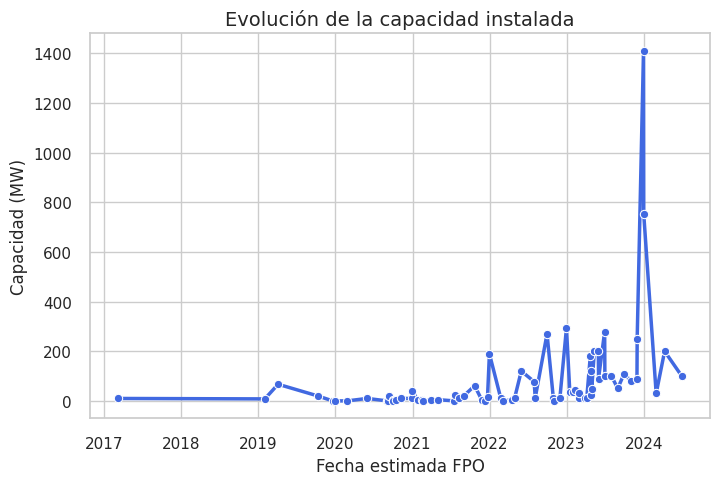

In [106]:
df_filtrado = df_B[df_B['Fecha estimada FPO'] >= '2016']


df_group = df_filtrado.groupby('Fecha estimada FPO')['Capacidad'].sum().reset_index()

sns.set_theme(style="whitegrid")

plt.figure(figsize=(8,5))
sns.lineplot(
    data=df_group,
    x='Fecha estimada FPO',
    y='Capacidad',
    color="royalblue",
    linewidth=2.5,
    marker="o"
)

plt.title("Evolución de la capacidad instalada", fontsize=14)
plt.xlabel("Fecha estimada FPO")
plt.ylabel("Capacidad (MW)")
plt.show()

#**VEAMOS LOS DATOS MEDIANTE GRAFICOS**

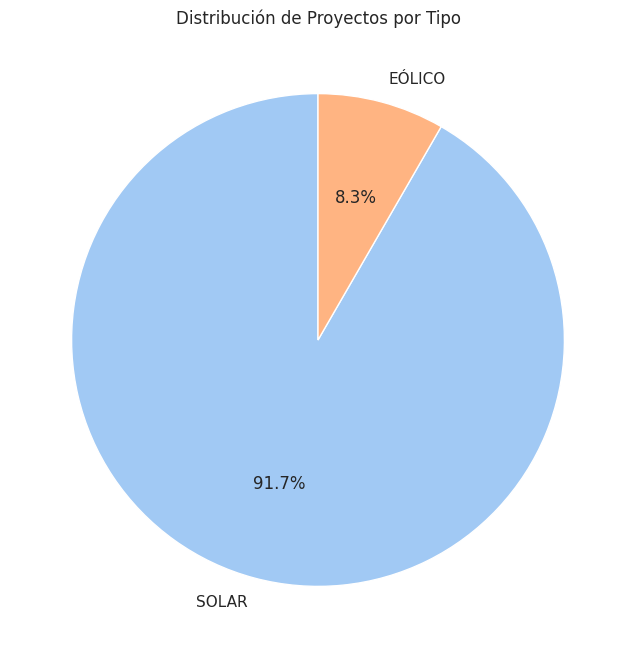

In [107]:
df_type_counts = df_B['Tipo'].value_counts().reset_index()
df_type_counts.columns = ['Tipo', 'Count']

plt.figure(figsize=(8, 8))
plt.pie(df_type_counts['Count'], labels=df_type_counts['Tipo'], autopct='%1.1f%%', startangle=90, colors=sns.color_palette('pastel'))
plt.title("Distribución de Proyectos por Tipo")
plt.show()

In [108]:
fig = px.histogram(
    df_B,
    x="Capacidad",
    nbins=15,
    title="Distribución de la Capacidad",
    labels={"Capacidad": "Capacidad (MW)"},
    color_discrete_sequence=["royalblue"]
)

fig.update_traces(marker_line_color="black", marker_line_width=1)
fig.update_layout(
    title_font_size=14,
    xaxis_title_font_size=12,
    yaxis_title="Frecuencia"
)

fig.show()

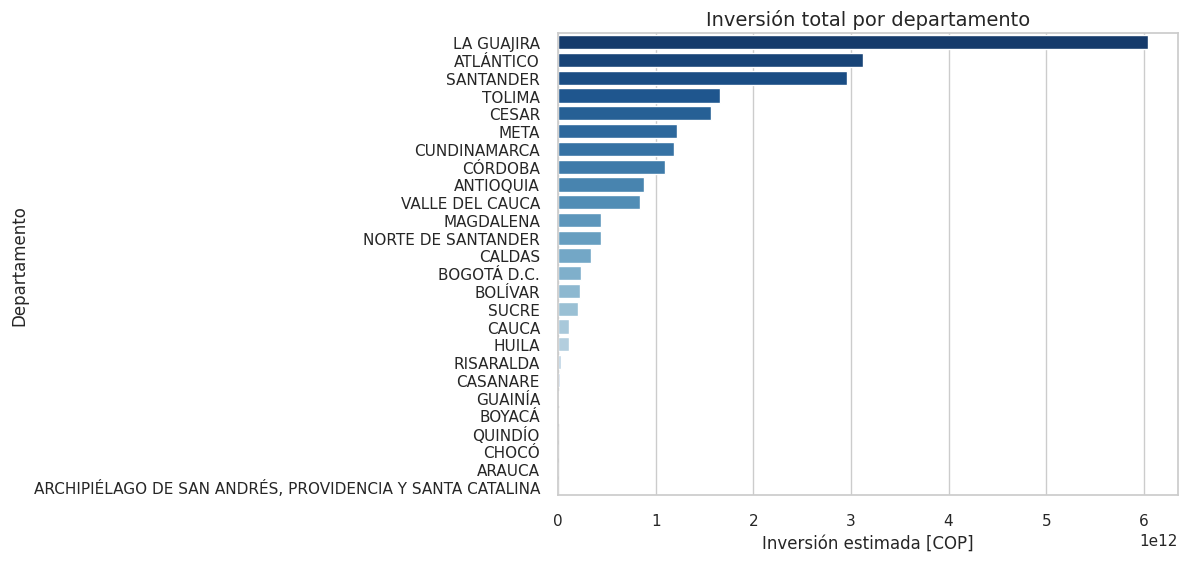

In [109]:
df_inv = df_B.groupby('Departamento')['Inversión estimada [COP]'].sum().sort_values(ascending=False).reset_index()

sns.set_theme(style="whitegrid")

plt.figure(figsize=(8,6))
sns.barplot(
    data=df_inv,
    x='Inversión estimada [COP]',
    y='Departamento',
    hue="Departamento",
    palette='Blues_r'
)

plt.title("Inversión total por departamento", fontsize=14)
plt.xlabel("Inversión estimada [COP]")
plt.ylabel("Departamento")
plt.show()

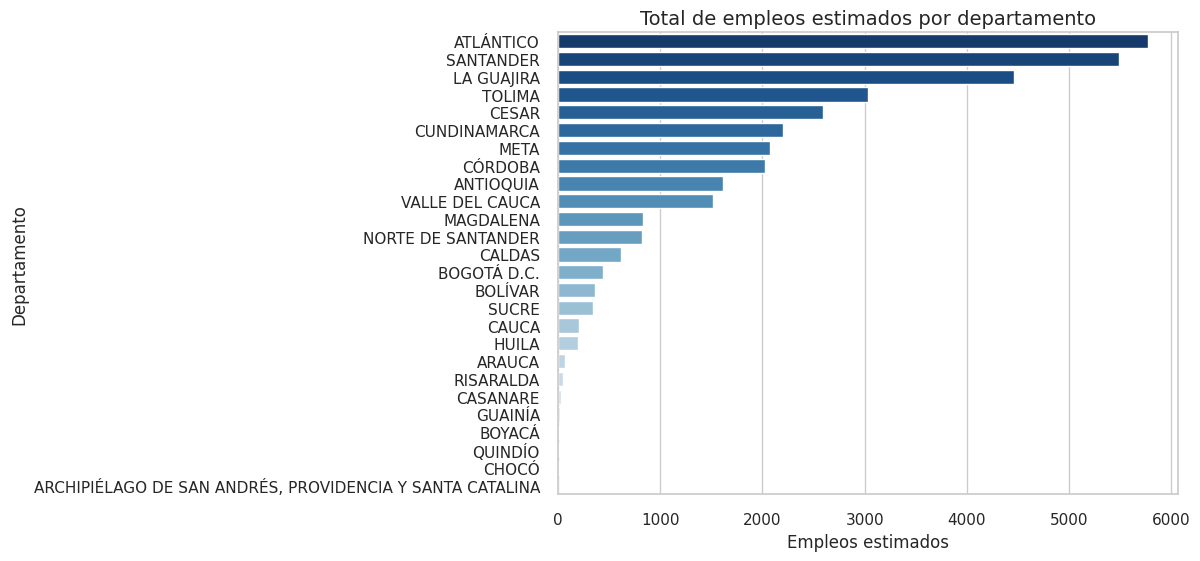

In [110]:
df_inv = df_B.groupby('Departamento')['Empleos estimados'].sum().sort_values(ascending=False).reset_index()

sns.set_theme(style="whitegrid")

plt.figure(figsize=(8,6))
sns.barplot(
    data=df_inv,
    x='Empleos estimados',
    y='Departamento',
    hue="Departamento",
    palette='Blues_r'
)

plt.title("Total de empleos estimados por departamento", fontsize=14)
plt.xlabel("Empleos estimados")
plt.ylabel("Departamento")
plt.show()

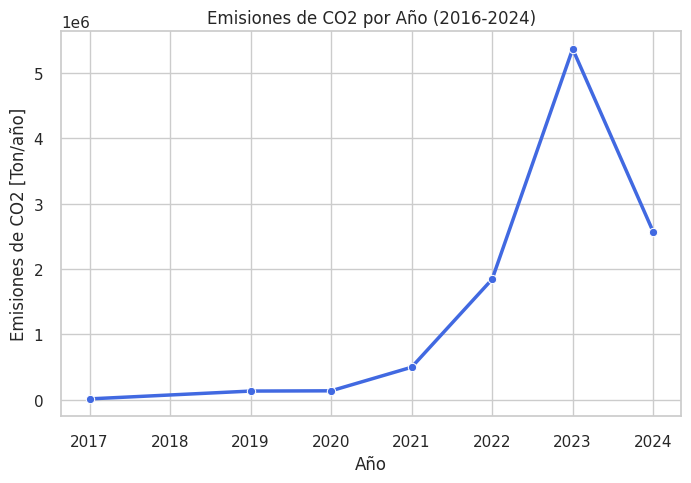

In [111]:
df_temp = df_B[(df_B['Fecha estimada FPO'].dt.year >= 2016) & (df_B['Fecha estimada FPO'].dt.year <= 2024)].copy()


df_temp['Año'] = df_temp['Fecha estimada FPO'].dt.year


df_emisiones_por_año = df_temp.groupby('Año')['Emisiones CO2 [Ton/año]'].sum().reset_index()


sns.set_theme(style="whitegrid")

plt.figure(figsize=(8,5))
sns.lineplot(
    data=df_emisiones_por_año,
    x='Año',
    y='Emisiones CO2 [Ton/año]',
    color="royalblue",
    linewidth=2.5,
    marker="o"
)

plt.title("Emisiones de CO2 por Año (2016-2024)")
plt.xlabel("Año")
plt.ylabel("Emisiones de CO2 [Ton/año]")
plt.grid(True)
plt.show()

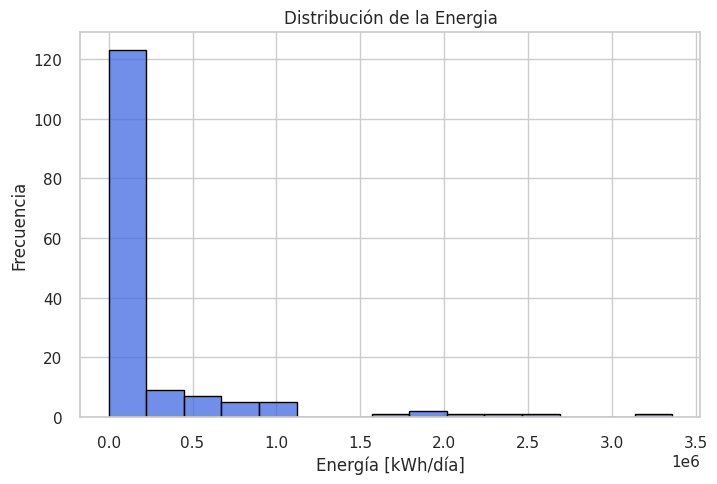

In [112]:
sns.set_theme(style="whitegrid")

plt.figure(figsize=(8,5))
sns.histplot(
    data=df_B,
    x='Energía [kWh/día]',
    bins=15,
    color='royalblue',
    edgecolor='black'
)

plt.title("Distribución de la Energia")
plt.xlabel("Energía [kWh/día]")
plt.ylabel("Frecuencia")
plt.show()

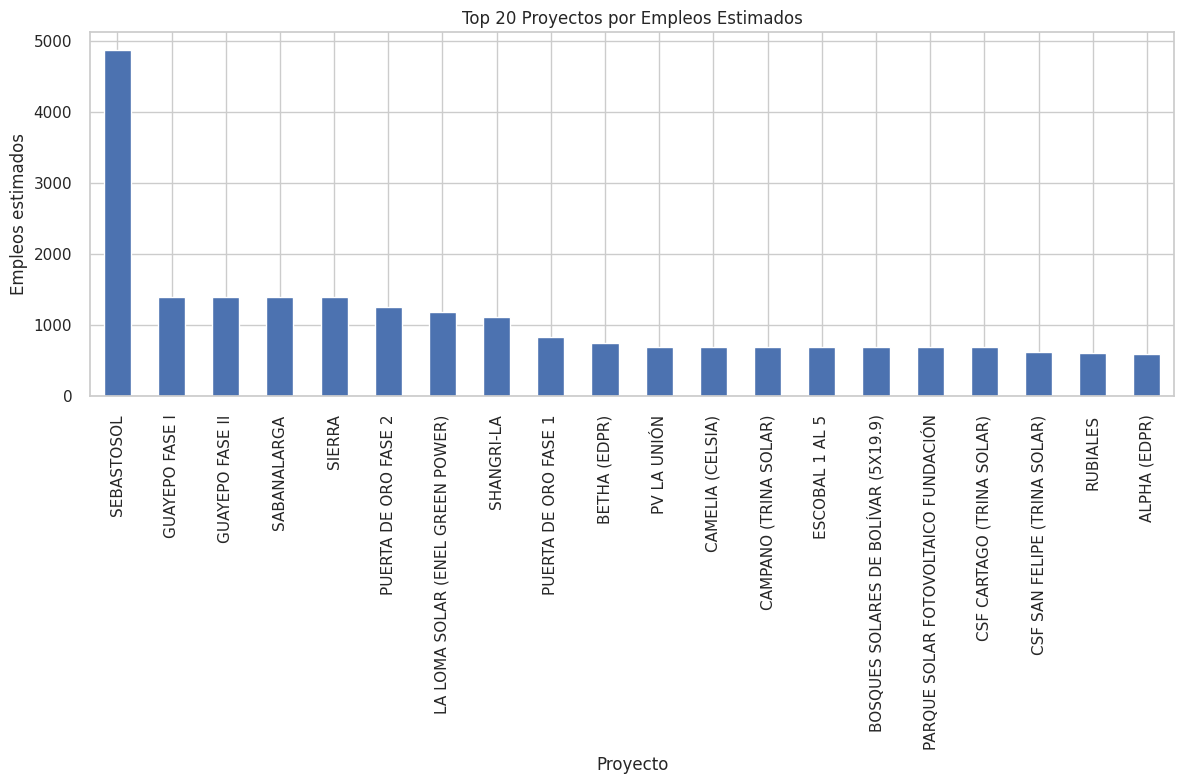

In [113]:
plt.figure(figsize=(12, 8))
df_B.groupby('Proyecto')['Empleos estimados'].sum().sort_values(ascending=False).head(20).plot(kind='bar')
plt.title('Top 20 Proyectos por Empleos Estimados')
plt.xlabel('Proyecto')
plt.ylabel('Empleos estimados')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

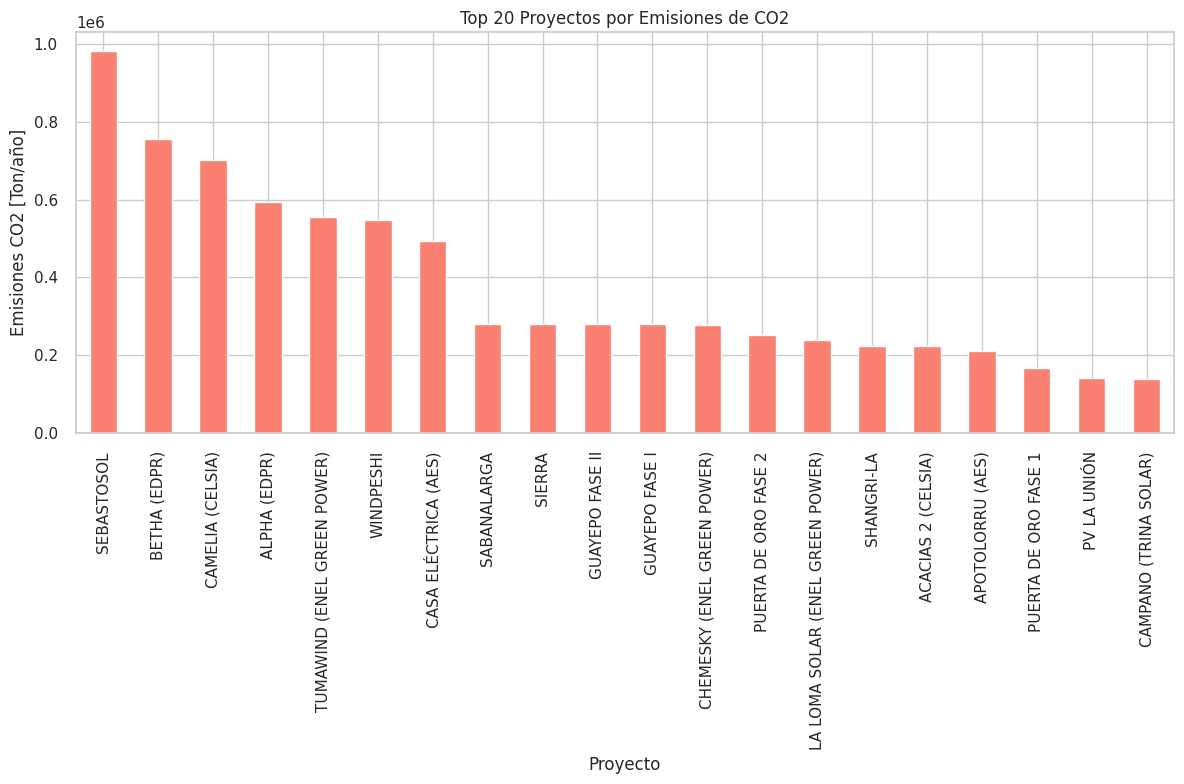

In [114]:
plt.figure(figsize=(12, 8))
df_B.groupby('Proyecto')['Emisiones CO2 [Ton/año]'].sum().sort_values(ascending=False).head(20).plot(kind='bar', color='salmon')
plt.title('Top 20 Proyectos por Emisiones de CO2')
plt.xlabel('Proyecto')
plt.ylabel('Emisiones CO2 [Ton/año]')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

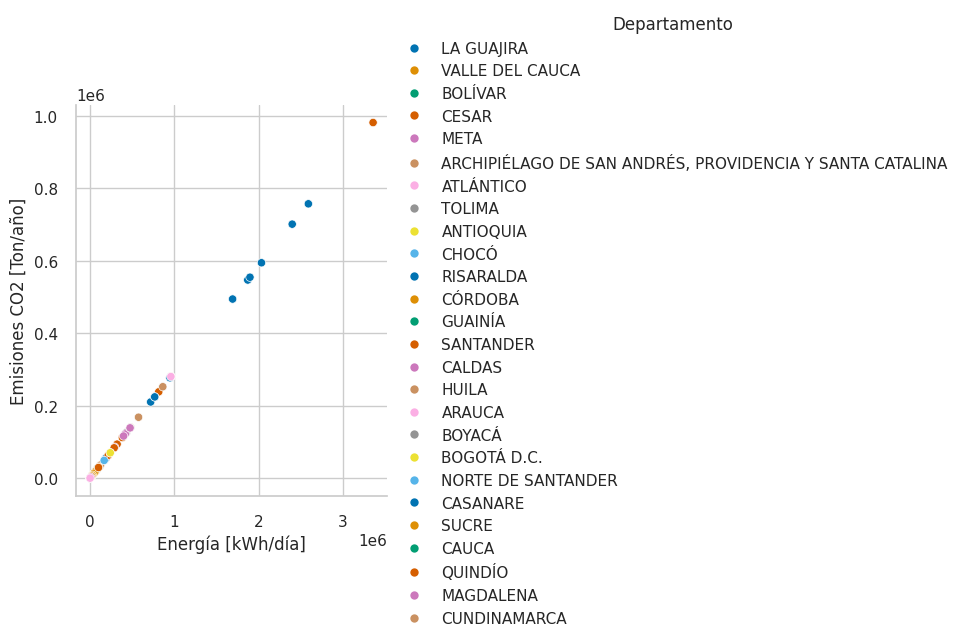

In [115]:
df_B.columns
sns.relplot(df_B,
            x = "Energía [kWh/día]",
            y = "Emisiones CO2 [Ton/año]",
            kind="scatter",
            hue = "Departamento",
            palette = "colorblind");

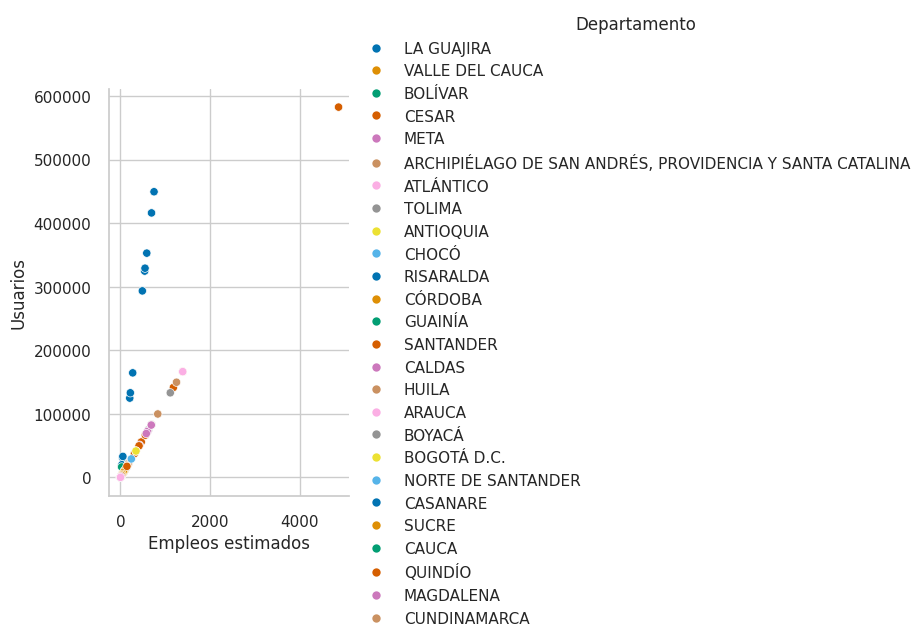

In [116]:
df_B.columns
sns.relplot(df_B,
            x = "Empleos estimados",
            y = "Usuarios",
            kind="scatter",
            hue = "Departamento",
            palette = "colorblind");

# Mapas de colombia con geopandas:

In [117]:
!pip install geopandas

In [118]:
import geopandas as gpd

try:
    colombia_geo = gpd.read_file("/content/co.json")

    display(colombia_geo.head())
    display(colombia_geo.columns)

except Exception as e:
    print(f"No se pudo cargar el archivo como GeoDataFrame: {e}")

,source,id,name,geometry
0,https://simplemaps.com,CONAR,Nariño,"MULTIPOLYGON (((-78.0739 2.64682, -77.98392 2...."
1,https://simplemaps.com,COPUT,Putumayo,"POLYGON ((-77.10386 0.35414, -77.10188 0.3607,..."
2,https://simplemaps.com,COCHO,Chocó,"MULTIPOLYGON (((-76.98546 8.25618, -76.98426 8..."
3,https://simplemaps.com,COGUA,Guainía,"POLYGON ((-69.84118 1.70758, -69.84155 1.7078,..."
4,https://simplemaps.com,COVAU,Vaupés,"POLYGON ((-70.10497 2.10116, -70.1083 2.05879,..."


Index(['source', 'id', 'name', 'geometry'], dtype='object')

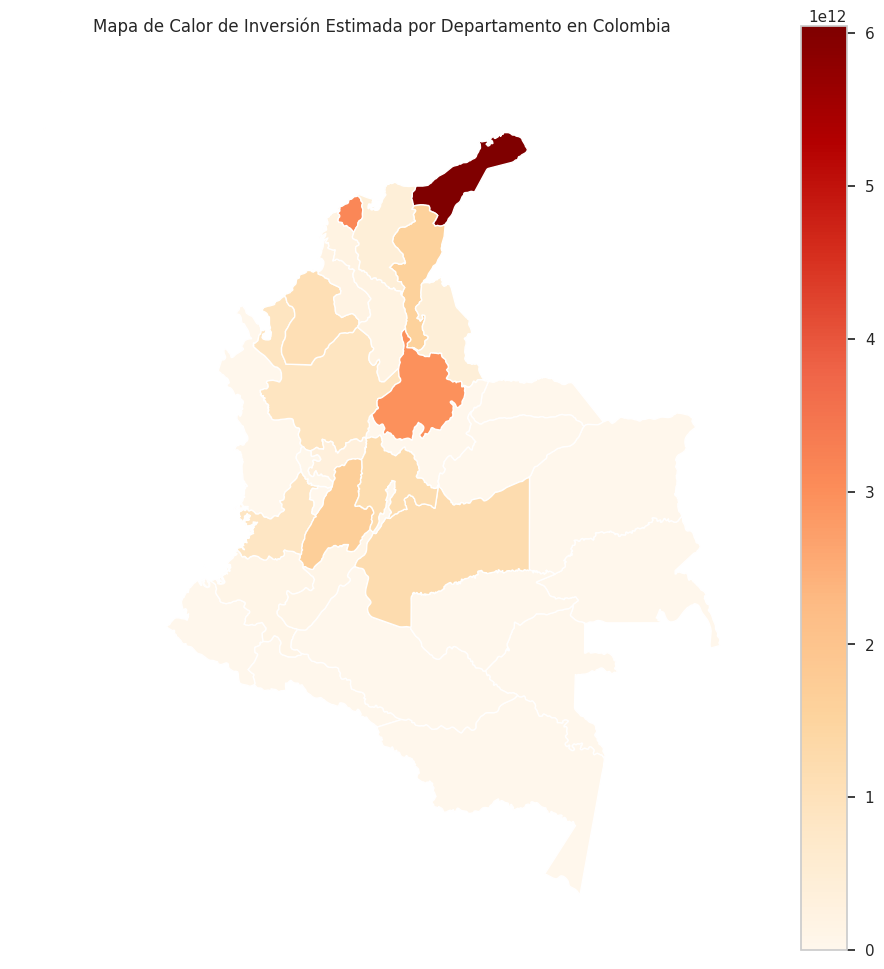

In [119]:
df_inversion_depto = df_B.groupby('Departamento')['Inversión estimada [COP]'].sum().reset_index()

df_inversion_depto['Departamento'] = df_inversion_depto['Departamento'].str.upper()
colombia_geo['name'] = colombia_geo['name'].str.upper()

colombia_inversion_geo = colombia_geo.merge(df_inversion_depto, left_on='name', right_on='Departamento', how='left')

colombia_inversion_geo['Inversión estimada [COP]'] = colombia_inversion_geo['Inversión estimada [COP]'].fillna(0)

fig, ax = plt.subplots(1, 1, figsize=(12, 12))
colombia_inversion_geo.plot(column='Inversión estimada [COP]', ax=ax, legend=True,
                           cmap='OrRd',
                           missing_kwds={'color': 'lightgrey'}
                          )

ax.set_title("Mapa de Calor de Inversión Estimada por Departamento en Colombia")
ax.set_axis_off()
plt.show()

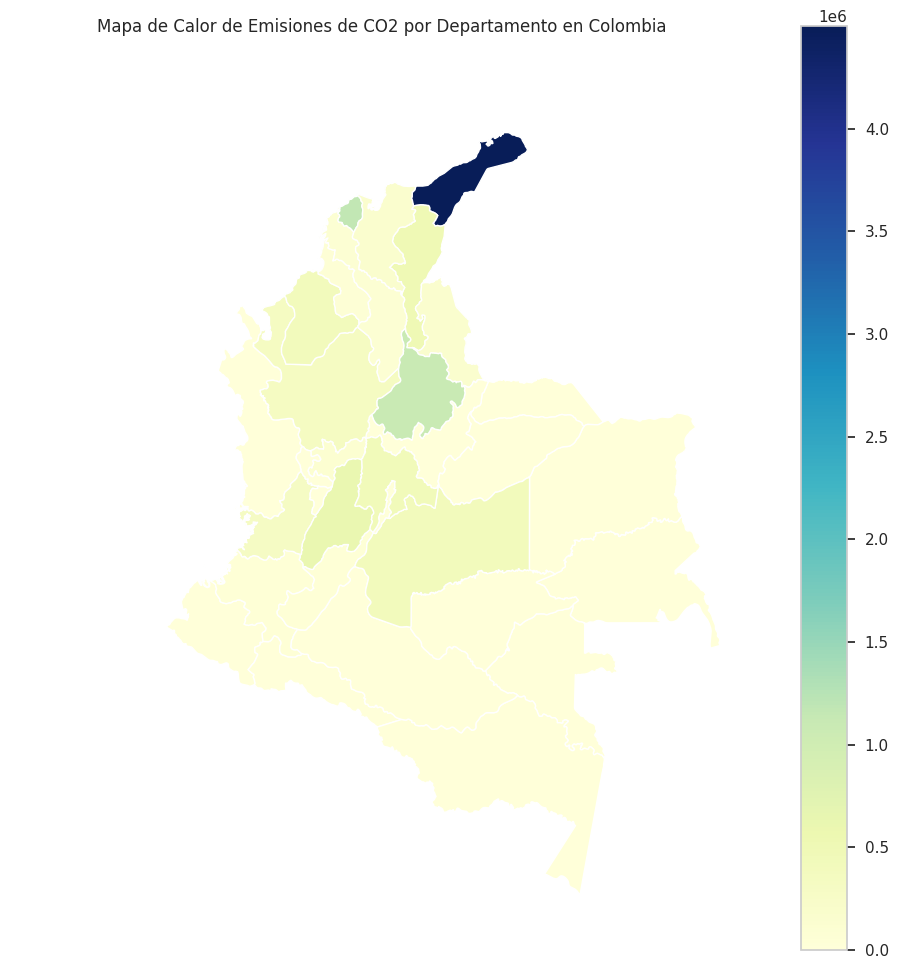

In [120]:
df_emisiones_depto = df_B.groupby('Departamento')['Emisiones CO2 [Ton/año]'].sum().reset_index()


df_emisiones_depto['Departamento'] = df_emisiones_depto['Departamento'].str.upper()
colombia_geo['name'] = colombia_geo['name'].str.upper()

colombia_emisiones_geo = colombia_geo.merge(df_emisiones_depto, left_on='name', right_on='Departamento', how='left')

colombia_emisiones_geo['Emisiones CO2 [Ton/año]'] = colombia_emisiones_geo['Emisiones CO2 [Ton/año]'].fillna(0)

fig, ax = plt.subplots(1, 1, figsize=(12, 12))
colombia_emisiones_geo.plot(column='Emisiones CO2 [Ton/año]', ax=ax, legend=True,
                           cmap='YlGnBu',
                           missing_kwds={'color': 'lightgrey'}
                          )

ax.set_title("Mapa de Calor de Emisiones de CO2 por Departamento en Colombia")
ax.set_axis_off()
plt.show()

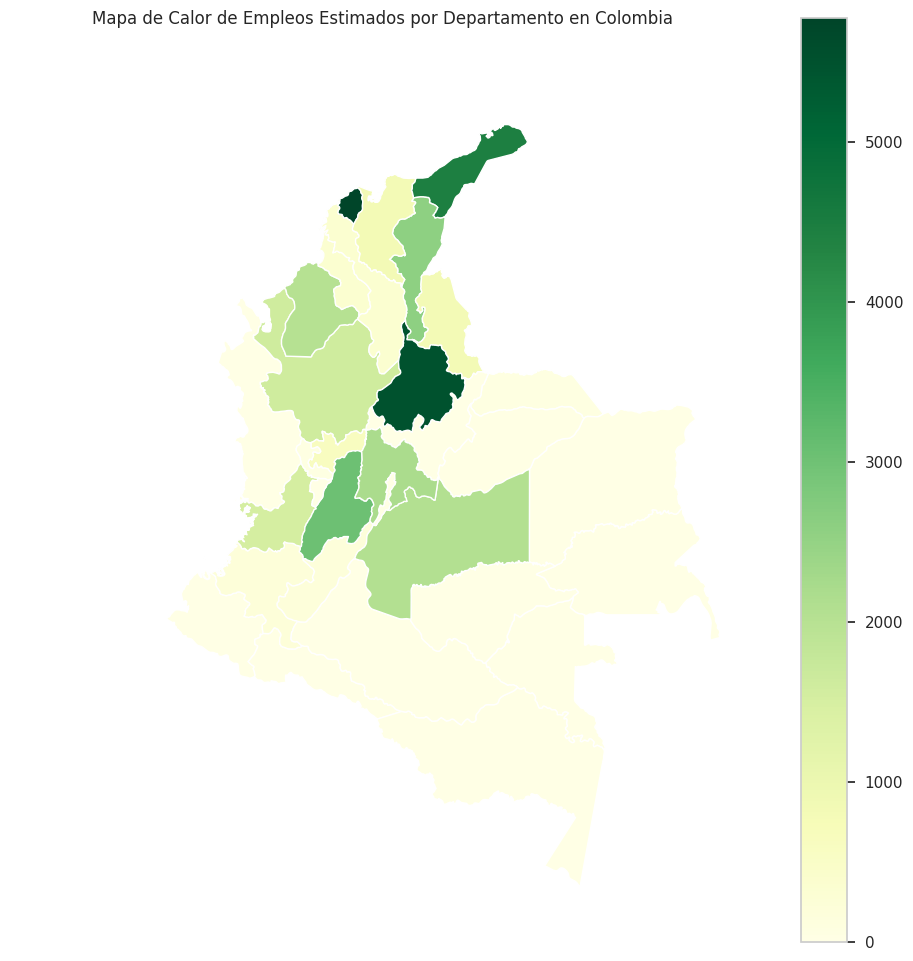

In [121]:
df_empleos_depto = df_B.groupby('Departamento')['Empleos estimados'].sum().reset_index()

df_empleos_depto['Departamento'] = df_empleos_depto['Departamento'].str.upper()
colombia_geo['name'] = colombia_geo['name'].str.upper()

colombia_empleos_geo = colombia_geo.merge(df_empleos_depto, left_on='name', right_on='Departamento', how='left')

colombia_empleos_geo['Empleos estimados'] = colombia_empleos_geo['Empleos estimados'].fillna(0)

fig, ax = plt.subplots(1, 1, figsize=(12, 12))
colombia_empleos_geo.plot(column='Empleos estimados', ax=ax, legend=True,
                           cmap='YlGn',
                           missing_kwds={'color': 'lightgrey'}
                          )

ax.set_title("Mapa de Calor de Empleos Estimados por Departamento en Colombia")
ax.set_axis_off()
plt.show()

# Matrices de correlacion

,Capacidad,Código Departamento,Código Municipio,Energía [kWh/día],Usuarios,Inversión estimada [COP],Empleos estimados,Emisiones CO2 [Ton/año]
Capacidad,1.000000,-0.042419,-0.019277,0.932136,0.932136,0.999439,0.944162,0.932136
Código Departamento,-0.042419,1.000000,0.932052,-0.026157,-0.026157,-0.045328,-0.052136,-0.026157
Código Municipio,-0.019277,0.932052,1.000000,-0.002143,-0.002143,-0.021630,-0.032518,-0.002143
Energía [kWh/día],0.932136,-0.026157,-0.002143,1.000000,1.000000,0.930226,0.760780,1.000000
Usuarios,0.932136,-0.026157,-0.002143,1.000000,1.000000,0.930226,0.760780,1.000000
Inversión estimada [COP],0.999439,-0.045328,-0.021630,0.930226,0.930226,1.000000,0.944894,0.930226
Empleos estimados,0.944162,-0.052136,-0.032518,0.760780,0.760780,0.944894,1.000000,0.760780
Emisiones CO2 [Ton/año],0.932136,-0.026157,-0.002143,1.000000,1.000000,0.930226,0.760780,1.000000


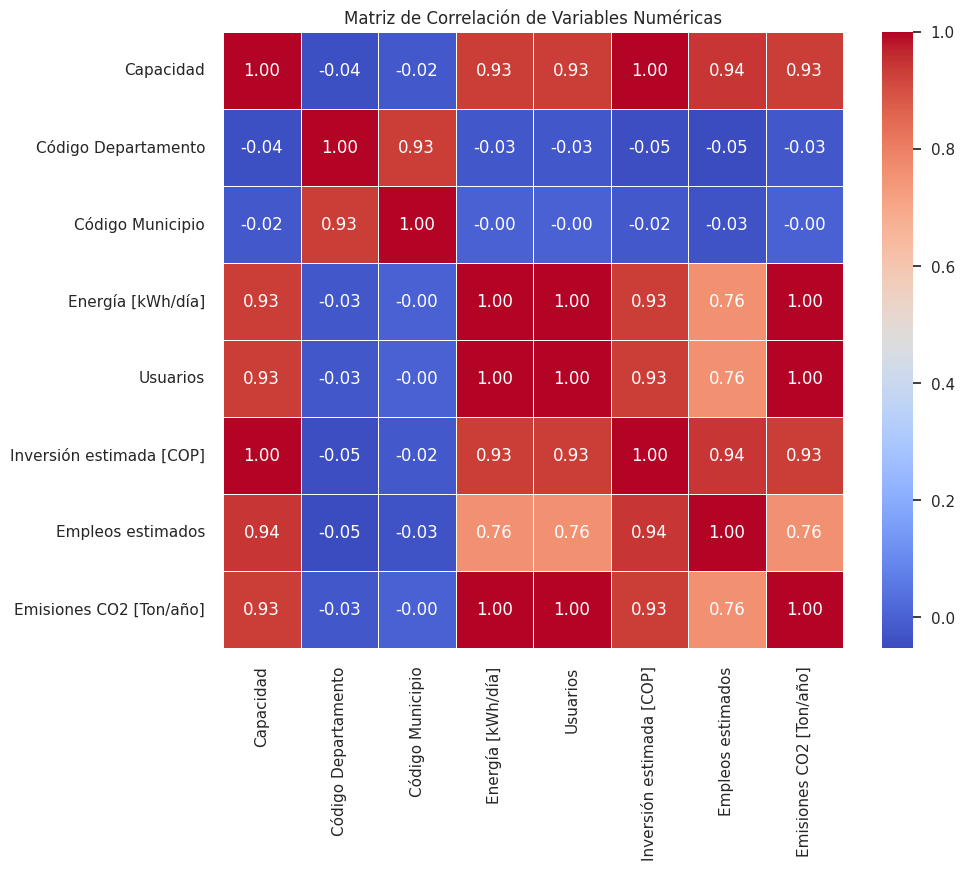

In [122]:
df_numeric = df_B.select_dtypes(include=[np.number])

correlacion = df_numeric.corr()

display(correlacion)

plt.figure(figsize=(10, 8))
sns.heatmap(correlacion, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
plt.title('Matriz de Correlación de Variables Numéricas')
plt.show()

In [123]:
df_B = df_B.drop(columns=['Capacidad', 'Usuarios', 'Inversión estimada [COP]', 'Código Municipio', 'Energía [kWh/día]'])

display(df_B.head())

,Proyecto,Tipo,Departamento,Municipio,Código Departamento,Fecha estimada FPO,Empleos estimados,Emisiones CO2 [Ton/año]
0,JEPIRACHI,EÓLICO,LA GUAJIRA,URIBIA,44,2004-04-27,51,51635
1,AUTOG CELSIA SOLAR YUMBO,SOLAR,VALLE DEL CAUCA,YUMBO,76,2017-03-09,68,13736
2,CELSIA SOLAR BOLIVAR,SOLAR,BOLÍVAR,SANTA ROSA,13,2019-02-01,56,11297
3,EL PASO SOLAR (ENEL GREEN POWER),SOLAR,CESAR,EL PASO,20,2019-04-05,466,93907
4,SOLAR CASTILLA ECP,SOLAR,META,CASTILLA LA NUEVA,50,2019-10-10,139,28032


,Código Departamento,Empleos estimados,Emisiones CO2 [Ton/año]
Código Departamento,1.000000,-0.052136,-0.026157
Empleos estimados,-0.052136,1.000000,0.760780
Emisiones CO2 [Ton/año],-0.026157,0.760780,1.000000


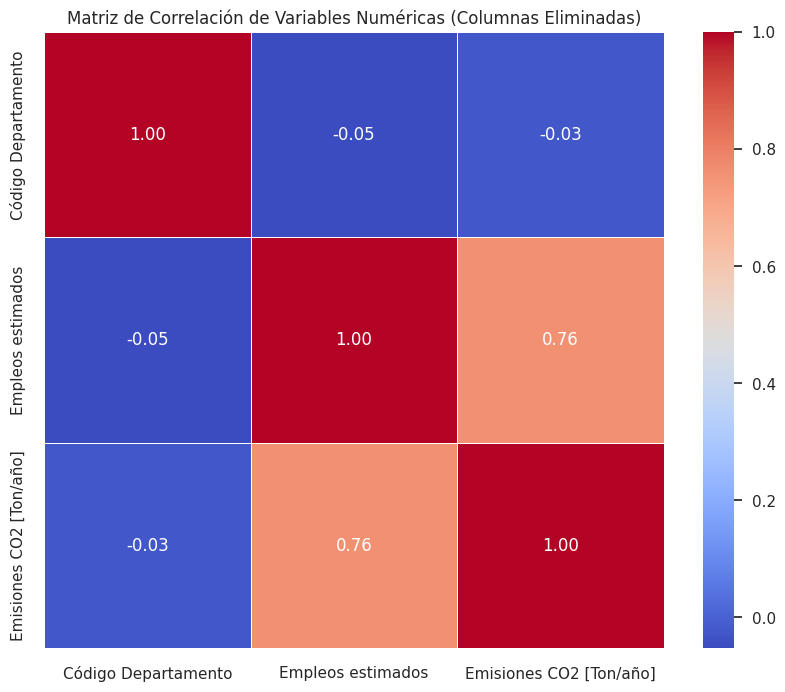

In [124]:
df_numeric = df_B.select_dtypes(include=[np.number])

correlacion = df_numeric.corr()

display(correlacion)

plt.figure(figsize=(10, 8))
sns.heatmap(correlacion, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
plt.title('Matriz de Correlación de Variables Numéricas (Columnas Eliminadas)')
plt.show()

# Agrupación de datos:

In [125]:
df_cluster = df_B[['Empleos estimados', 'Emisiones CO2 [Ton/año]']]
display(df_cluster.head())

,Empleos estimados,Emisiones CO2 [Ton/año]
0,51,51635
1,68,13736
2,56,11297
3,466,93907
4,139,28032


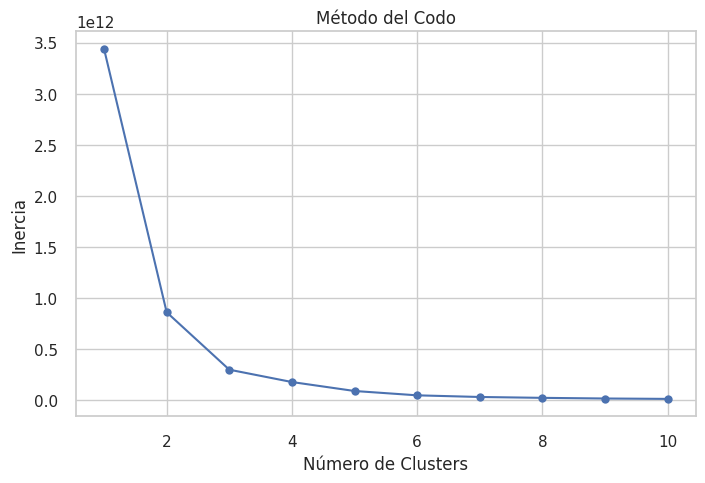

In [126]:
from sklearn.cluster import KMeans
from yellowbrick.cluster import KElbowVisualizer

inercia = []
for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, random_state=42, n_init=10)
    kmeans.fit(df_cluster)
    inercia.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), inercia, marker='o')
plt.xlabel('Número de Clusters')
plt.ylabel('Inercia')
plt.title('Método del Codo')
plt.show()

In [127]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
kmeans.fit(df_cluster)

df_B['cluster_label'] = kmeans.labels_

display(df_B.head())

,Proyecto,Tipo,Departamento,Municipio,Código Departamento,Fecha estimada FPO,Empleos estimados,Emisiones CO2 [Ton/año],cluster_label
0,JEPIRACHI,EÓLICO,LA GUAJIRA,URIBIA,44,2004-04-27,51,51635,1
1,AUTOG CELSIA SOLAR YUMBO,SOLAR,VALLE DEL CAUCA,YUMBO,76,2017-03-09,68,13736,1
2,CELSIA SOLAR BOLIVAR,SOLAR,BOLÍVAR,SANTA ROSA,13,2019-02-01,56,11297,1
3,EL PASO SOLAR (ENEL GREEN POWER),SOLAR,CESAR,EL PASO,20,2019-04-05,466,93907,1
4,SOLAR CASTILLA ECP,SOLAR,META,CASTILLA LA NUEVA,50,2019-10-10,139,28032,1


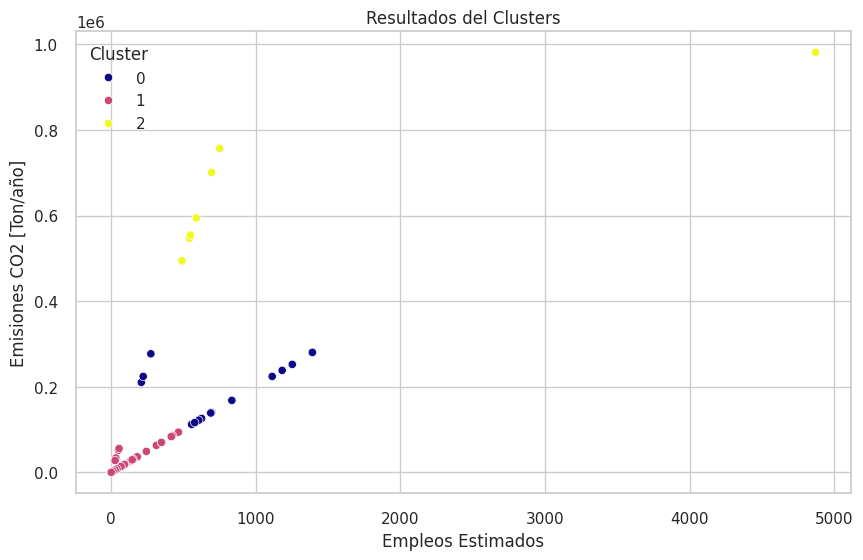

In [128]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_B, x='Empleos estimados', y='Emisiones CO2 [Ton/año]', hue='cluster_label', palette='plasma')
plt.title('Resultados del Clusters')
plt.xlabel('Empleos Estimados')
plt.ylabel('Emisiones CO2 [Ton/año]')
plt.legend(title='Cluster')
plt.show()

# Conclución de las agrupaciones:

In [129]:
cluster_analysis = df_B.groupby('cluster_label')[['Empleos estimados', 'Emisiones CO2 [Ton/año]']].mean()
display(cluster_analysis)

print("Interpretacion de Clústers:")
print("Clúster 0: Proyectos con empleo estimado relativamente bajo y bajas emisiones de CO2.")
print("Clúster 1: Proyectos con empleo estimado moderado y emisiones de CO2 moderadas.")
print("Clúster 2: Proyectos con alto empleo estimado y altas emisiones de CO2, que representan proyectos de mayor escala.")

,Empleos estimados,Emisiones CO2 [Ton/año]
cluster_label,,
0,818.142857,191858.952381
1,71.054688,15339.617188
2,1212.714286,661194.714286


Interpretacion de Clústers:
Clúster 0: Proyectos con empleo estimado relativamente bajo y bajas emisiones de CO2.
Clúster 1: Proyectos con empleo estimado moderado y emisiones de CO2 moderadas.
Clúster 2: Proyectos con alto empleo estimado y altas emisiones de CO2, que representan proyectos de mayor escala.
